# M2 — G1 đi bộ trên mặt phẳng 
Train M2 (MLP 896-448-128, input `o_t`) bằng MuJoCo Playground + Brax PPO trên Kaggle (2×T4).

- Môi trường: địa hình `flat` + cấu hình của Minh (`configs/terrain.yaml`, `UnifiedG1TerrainEnv`) — **không sửa**.
- Phần thêm mới nằm trong `flat_walking/` (xem `flat_walking/readme_report.md`).
- Chạy lần lượt từ Cell 1. Cell 5 là kiểm tra nhanh, nên chạy trước Cell 6 (train).

In [8]:
# Cell 1: Kiểm tra GPU
import subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=index,name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout)

0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB



In [30]:
# Cell 2: Clone / cập nhật repo (nhánh M2)
import os, subprocess
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/Bipedal-Locomotion")
if not PROJECT_DIR.exists():
    subprocess.check_call(["git", "clone", "--branch", "M2",
                           "https://github.com/TotallyNotMinh/Bipedal-Locomotion.git", str(PROJECT_DIR)])
else:
    subprocess.check_call(["git", "-C", str(PROJECT_DIR), "pull"])
os.chdir(PROJECT_DIR)
print("Working dir:", os.getcwd())
print(subprocess.run(["git", "log", "-1", "--format=%h %an %s"], capture_output=True, text=True).stdout)

Already up to date.
Working dir: /kaggle/working/Bipedal-Locomotion
900db09 OanhKim-tmd fix(M2): compute body velocity from qpos/qvel in eval; add demo video script and cell



In [10]:
# Cell 3: Cài dependencies
import sys, subprocess

pkgs = ["brax", "flax", "optax", "orbax-checkpoint", "ml_collections", "pyyaml",
        "lxml", "etils", "tqdm"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade"] + pkgs)

try:
    import mujoco_playground
    print("[OK] mujoco_playground already installed")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "--no-deps",
        "git+https://github.com/google-deepmind/mujoco_playground.git@v0.2.0"])
    print("[OK] mujoco_playground installed")

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'
[OK] mujoco_playground already installed


In [11]:
# Cell 4: Kiểm tra JAX / GPU
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.85"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
import jax
print(f"JAX {jax.__version__}:", jax.devices())

JAX 0.11.1: [CudaDevice(id=0), CudaDevice(id=1)]


In [13]:
# Cell 5: Kiểm tra nhanh môi trường
import subprocess, sys
r = subprocess.run([sys.executable, "flat_walking/train_m2_flat.py", "--smoke"],
                   capture_output=True, text=True)
print(r.stdout[-3000:]); print(r.stderr[-1500:] if r.returncode else "")
assert r.returncode == 0, "smoke test lỗi — đừng chạy Cell 6"

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'
[smoke] Minh terrain: flat d=0.0 80.0x80.0 m, grid=(1000, 1000), height=[0.000, 0.000]
[smoke] nu=29 nhfield=1 hfield_size=[40.0, 40.0, 0.01, 0.05] floor_geom_type=mjGEOM_HFIELD
[smoke] obs_size={'privileged_state': (216,), 'state': (103,)}
[smoke] spawn xyz=(42.76, 23.48, 0.755)  (arena 80.0x80.0)  command=[ 0.57979214 -0.20242482 -0.05027163]
[smoke] sau 20 bước: z=0.698 reward=-0.0091 done=0.0
[smoke] OK




In [14]:
# Cell 6: TRAIN M2 (100M bước, ~vài chục phút -> vài giờ tuỳ GPU)
import subprocess, sys

NUM_TIMESTEPS = None     # None = lấy từ flat_walking/m2_flat.yaml (100M). Thử nhanh: 2_000_000
cmd = [sys.executable, "-u", "flat_walking/train_m2_flat.py"]
if NUM_TIMESTEPS:
    cmd += ["--num-timesteps", str(NUM_TIMESTEPS)]

proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in proc.stdout:
    print(line, end="")
assert proc.wait() == 0, "train lỗi"

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'
[+] JAX devices (2): ['cuda:0', 'cuda:1']
[+] Minh env: category=flat d=0.0 arena=80.0x80.0m grid=(1000, 1000) num_envs=4096
[+] Minh commands: vx=(0.2, 1.0) vy=(-0.3, 0.3) wz=(-0.5, 0.5)  push=False friction_switch=False
[+] obs_size={'privileged_state': (216,), 'state': (103,)} action_size=29 episode_length=1000
[+] M2 params: {'policy_input_dim': 103, 'value_input_dim': 216, 'policy_params': 559994, 'value_params': 275457}
[+] Output: /kaggle/working/Bipedal-Locomotion/results/flat/g1_flat_m2_20261126_083748
[+] Starting PPO training...
  step=          0  elapsed=   473s  sps=        0  eval_reward= -3.178  eval_len=  52.5
  step=  5,406,720  elapsed=  1548s  sps=    3,492  eval_reward= -1.381  eval_len=  57.6
  step= 10,813,440  elapsed=  2319s  sps=    4,663  eval_reward= -1.028  eval_len=  85.7
  step= 16,220,160  elapsed=  3008s  sps=    5,392  eval_reward=  0.538  eval_len= 167.4

In [15]:
# Cell 7: Nén kết quả để tải về (results/flat -> /kaggle/working/m2_flat_results.zip)
import shutil
print(shutil.make_archive("/kaggle/working/m2_flat_results", "zip", "results/flat"))

/kaggle/working/m2_flat_results.zip


## Đánh giá kết quả train
Cell 8: kiểm tra + sao lưu checkpoint. Cell 9: phân tích đường cong train. Cell 10: rollout policy đã lưu, đo khả năng bám lệnh vận tốc. Logic nằm trong `flat_walking/eval_m2_flat.py`.

In [21]:
# Cell 8: Kiểm tra checkpoint đã lưu chưa + sao lưu (/kaggle/working/m2_flat_backup)
import subprocess, sys
r = subprocess.run([sys.executable, 'flat_walking/eval_m2_flat.py', '--check',
                    '--backup-dir', '/kaggle/working/m2_flat_backup'], capture_output=True, text=True)
print(r.stdout); print(r.stderr[-1500:] if r.returncode else '')

=== CHECKPOINT: /kaggle/working/Bipedal-Locomotion/results/flat/g1_flat_m2_20261126_083748
  [OK] step   5,406,720: 13 file, 3.11 MB
  [OK] step  10,813,440: 14 file, 3.11 MB
  [OK] step  16,220,160: 15 file, 3.12 MB
  [OK] step  21,626,880: 14 file, 3.12 MB
  [OK] step  27,033,600: 14 file, 3.12 MB
  [OK] step  32,440,320: 14 file, 3.12 MB
  [OK] step  37,847,040: 14 file, 3.12 MB
  [OK] step  43,253,760: 14 file, 3.12 MB
  [OK] step  48,660,480: 14 file, 3.12 MB
  [OK] step  54,067,200: 14 file, 3.12 MB
  [OK] step  59,473,920: 14 file, 3.12 MB
  [OK] step  64,880,640: 13 file, 3.12 MB
  [OK] step  70,287,360: 14 file, 3.12 MB
  [OK] step  75,694,080: 14 file, 3.12 MB
  [OK] step  81,100,800: 14 file, 3.12 MB
  [OK] step  86,507,520: 14 file, 3.13 MB
  [OK] step  91,914,240: 14 file, 3.13 MB
  [OK] step  97,320,960: 14 file, 3.13 MB
  [OK] step 102,727,680: 14 file, 3.13 MB
  [OK] resolved_config.yaml
  [OK] metrics.jsonl
  [OK] run_metadata.json
  Thời gian train: 14029s | params: {

=== ĐƯỜNG CONG TRAIN (20 lần eval, tới 102,727,680 bước)
  reward cuối: 42.28 | tốt nhất: 42.28 @ 102,727,680
  trung bình 3 eval cuối: 41.39 ± 0.67
  tăng trong nửa sau train: +2.93 (+7.4%)  -> còn đang cải thiện
  độ dài episode cuối: 1000/1000 | đạt >=95% mức max từ 32,440,320 bước
  Thành phần reward (eval cuối):
    reward/tracking_lin_vel              929.263
    reward/feet_phase                    865.560
    reward/tracking_ang_vel              668.554
    reward/feet_slip                    -168.987
    reward/joint_deviation_hip           -68.060
    swing_peak                            57.300
    reward/pose                          -47.626
    reward/joint_deviation_knee          -38.787
    reward/orientation                   -18.211
    reward/ang_vel_xy                    -15.054
    reward/feet_air_time                  14.200
    reward/contact_force                  -6.961
    reward/collision                      -0.130
    reward/dof_pos_limits                 -0

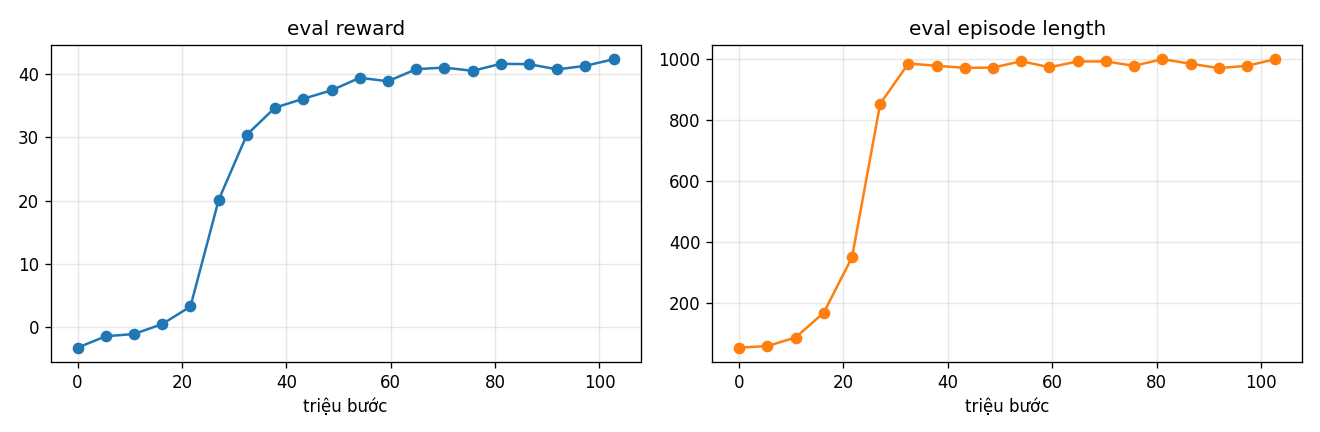

In [22]:
# Cell 9: Phân tích đường cong train (reward, độ dài episode, hội tụ, thành phần reward)
r = subprocess.run([sys.executable, 'flat_walking/eval_m2_flat.py', '--curves'], capture_output=True, text=True)
print(r.stdout); print(r.stderr[-1500:] if r.returncode else '')
import glob; from IPython.display import Image, display
for p in glob.glob('results/flat/*/train_curves.png')[-1:]: display(Image(p))

In [31]:
# Cell 10: Rollout policy từ checkpoint cuối: sống sót, sai số bám vận tốc (vx, vy, wz)
r = subprocess.run([sys.executable, 'flat_walking/eval_m2_flat.py', '--rollout', '--n-envs', '64'],
                   capture_output=True, text=True)
print(r.stdout[-5000:]); print(r.stderr[-3000:] if r.returncode else '')

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'
=== ROLLOUT checkpoint 000102727680 | 64 env x 1000 bước (deterministic)
  Dải lệnh: vx=(0.2, 1.0) vy=(-0.3, 0.3) wz=(-0.5, 0.5)
  - ngẫu nhiên (dải của Minh)  sống sót 100.0% | len 1000.0 | RMSE vx 0.073 vy 0.119 wz 0.189 | TB vx +0.58 vy -0.03 wz +0.03
  - tiến vx=0.5                sống sót  98.4% | len  985.2 | RMSE vx 0.055 vy 0.108 wz 0.162 | TB vx +0.47 vy -0.04 wz -0.01
  - tiến vx=1.0                sống sót 100.0% | len 1000.0 | RMSE vx 0.080 vy 0.105 wz 0.179 | TB vx +0.94 vy -0.01 wz -0.01
  - đi ngang vy=0.3: bỏ qua (ngoài dải lệnh)
  - xoay wz=0.5: bỏ qua (ngoài dải lệnh)
  - đứng yên: bỏ qua (ngoài dải lệnh)
  [OK] Đã lưu: /kaggle/working/Bipedal-Locomotion/results/flat/g1_flat_m2_20261126_083748/eval_rollout.json
=== KẾT LUẬN TỰ ĐỘNG
  [ĐẠT] Sống sót >= 95% (lệnh ngẫu nhiên)
  [ĐẠT] RMSE vx < 0.25 m/s
  [ĐẠT] RMSE vy < 0.25 m/s
  [ĐẠT] RMSE wz < 0.30 rad/s
  (Ngưỡng là mức

In [28]:
# Cell 11: Nén lại lần nữa (gồm cả train_curves.png và eval_rollout.json)
import shutil
print(shutil.make_archive('/kaggle/working/m2_flat_results', 'zip', 'results/flat'))

/kaggle/working/m2_flat_results.zip


In [29]:
# Cell 12: Quay video demo (robot + vận tốc lệnh vs thực tế)
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imageio', 'imageio-ffmpeg'])
r = subprocess.run([sys.executable, 'flat_walking/make_demo_video.py'], capture_output=True, text=True)
print(r.stdout[-3000:]); print(r.stderr[-3000:] if r.returncode else '')
import glob; from IPython.display import Video, display
v = sorted(glob.glob('results/flat/*/demo_m2.mp4'))
if v:
    import shutil; shutil.copy(v[-1], '/kaggle/working/demo_m2.mp4')
    display(Video('/kaggle/working/demo_m2.mp4', embed=True, width=960))

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'
[+] Mô phỏng xong 900 bước (18.0s)
[OK] Đã lưu video: /kaggle/working/Bipedal-Locomotion/results/flat/g1_flat_m2_20261126_083748/demo_m2.mp4
RMSE theo lệnh: vx=0.116 vy=0.156 wz=0.202




In [32]:
# Cell 13: Test reload checkpoint + đo tài nguyên (phiên bản thư viện, VRAM, độ trễ suy luận)
import subprocess, sys
r = subprocess.run([sys.executable, 'flat_walking/eval_m2_flat.py', '--reload', '--resources'], capture_output=True, text=True)
print(r.stdout[-4000:]); print(r.stderr[-3000:] if r.returncode else '')


usage: eval_m2_flat.py [-h] [--results-dir RESULTS_DIR] [--run RUN]
                       [--backup-dir BACKUP_DIR] [--n-envs N_ENVS] [--check]
                       [--curves] [--rollout]
eval_m2_flat.py: error: unrecognized arguments: --reload --resources



In [33]:
# Cell 14: Unit test metric (không cần GPU)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pytest'])
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests/test_m2_metrics.py'], capture_output=True, text=True)
print(r.stdout[-2000:])


no tests ran in 0.00s

